#Imports
try to import required modules and libraries here.

In [1]:
import numpy as np
import pandas as pd
import torch
print("Ready.")

Ready.


#Data preprocessing



*   Use the mp-api and collect all the cif file mentioned in the csv file already given
*   create the graph and make the embeddings to so we can start working on it
*   try to document properly so we can easily catch context



In [2]:
import torch


!pip install torch_geometric --extra-index-url https://data.pyg.org/whl/


Looking in indexes: https://pypi.org/simple, https://data.pyg.org/whl/
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.7/63.7 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 30.8 MB/s eta 0:00:00


In [3]:
# DATA LOADING
# _________________________________________________________________________

import torch

graphs = torch.load("graphs.pt", map_location="cpu", weights_only=False)
graphs = [g for g in graphs if g is not None]

print("Total graphs:", len(graphs))
print(graphs[0])

Total graphs: 8129
Data(x=[4, 5], edge_index=[2, 32], edge_attr=[32, 1], y=[1], triplets=[60, 3], angles=[60, 1])


#Model

* making the main Physics informed GNN model.
* the details regarding to the model will be documented parallely

### **Making simple data-driven model**

In [4]:
print("Number of graphs:", len(graphs))

g = graphs[0]

print("Node feature shape:", g.x.shape)
print("Edge index shape:", g.edge_index.shape)
print("Target y:", g.y)
print("Num features:", g.num_features)

Number of graphs: 8129
Node feature shape: torch.Size([4, 5])
Edge index shape: torch.Size([2, 32])
Target y: tensor([-0.4133])
Num features: 5


In [5]:
all_y = torch.cat([d.y.view(-1).float() for d in graphs])

print("y min :", all_y.min().item())
print("y max :", all_y.max().item())
print("y mean:", all_y.mean().item())
print("y std :", all_y.std().item())

y min : -1.41457998752594
y max : 5.285358905792236
y mean: 0.17964598536491394
y std : 1.2559542655944824


In [6]:
import torch
import torch.nn.functional as F
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from torch_geometric.nn import SAGEConv, GATConv, GINConv, global_add_pool
from torch_geometric.loader import DataLoader

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [7]:
# DATA SPLITTING + LOADERS
# _________________________________________________________________________
# Train / Val / Test  →  80 / 10 / 10

from sklearn.model_selection import train_test_split
from torch_geometric.loader import DataLoader

train_data, temp_data = train_test_split(graphs, test_size=0.20, random_state=42)
val_data,   test_data = train_test_split(temp_data, test_size=0.50, random_state=42)

train_loader = DataLoader(train_data, batch_size=16, shuffle=True)
val_loader   = DataLoader(val_data,   batch_size=16, shuffle=False)
test_loader  = DataLoader(test_data,  batch_size=16, shuffle=False)

print("Train:", len(train_data))
print("Val:  ", len(val_data))
print("Test: ", len(test_data))

Train: 6503
Val:   813
Test:  813


In [8]:
from torch_geometric.nn import GINConv

class GINModel(torch.nn.Module):
    def __init__(self, in_channels):
        super().__init__()

        def mlp(in_f, out_f):
            return torch.nn.Sequential(
                torch.nn.Linear(in_f, out_f),
                torch.nn.ReLU(),
                torch.nn.Linear(out_f, out_f)
            )

        self.conv1 = GINConv(mlp(in_channels, 128))
        self.conv2 = GINConv(mlp(128, 128))
        self.conv3 = GINConv(mlp(128, 64))

        self.fc1 = torch.nn.Linear(64, 32)
        self.fc2 = torch.nn.Linear(32, 1)

        self.dropout = torch.nn.Dropout(0.1)

    def forward(self, x, edge_index, batch):

        x = F.relu(self.conv1(x, edge_index))
        x = F.relu(self.conv2(x, edge_index))
        x = F.relu(self.conv3(x, edge_index))

        x = global_add_pool(x, batch)

        x = self.dropout(F.relu(self.fc1(x)))
        x = self.fc2(x)

        return x.view(-1)

In [14]:
def get_optimizer(model):
    return torch.optim.Adam(
        model.parameters(),
        lr=0.001
    )

In [15]:
# TRAIN FUNCTION
# _________________________________________________________________________

def train_model():

    model     = GINModel(graphs[0].num_features).to(device)
    optimizer = get_optimizer(model)
    criterion = torch.nn.HuberLoss()

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=0.5, patience=5
    )

    train_losses = []
    val_losses   = []
    best_val     = float("inf")

    for epoch in range(100):

        # ── Train ──────────────────────────────────────────────────────────
        model.train()
        total_train = 0

        for batch in train_loader:
            batch = batch.to(device)
            optimizer.zero_grad()
            pred  = model(batch.x, batch.edge_index, batch.batch)
            loss  = criterion(pred, batch.y.view(-1).float())
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            total_train += loss.item()

        avg_train = total_train / len(train_loader)
        train_losses.append(avg_train)

        # ── Validation ─────────────────────────────────────────────────────
        model.eval()
        total_val = 0

        with torch.no_grad():
            for batch in val_loader:
                batch = batch.to(device)
                pred  = model(batch.x, batch.edge_index, batch.batch)
                loss  = criterion(pred, batch.y.view(-1).float())
                total_val += loss.item()

        avg_val = total_val / len(val_loader)
        val_losses.append(avg_val)
        scheduler.step(avg_val)

        if avg_val < best_val:
            best_val = avg_val
            torch.save(model.state_dict(), "Best_Adam.pth")

        print(f"Epoch {epoch+1:03d} | Train {avg_train:.4f} | Val {avg_val:.4f}")

    model.load_state_dict(torch.load("Best_Adam.pth", weights_only=True))
    return model, train_losses, val_losses

In [20]:
# EVALUATE FUNCTION
# _________________________________________________________________________

def evaluate(model, loader):

    model.eval()

    preds, trues = [], []

    with torch.no_grad():
        for batch in loader:
            batch = batch.to(device)

            pred = model(
                batch.x,
                batch.edge_index,
                batch.batch
            )

            preds.extend(pred.cpu().numpy())
            trues.extend(batch.y.view(-1).cpu().numpy())

    y_pred = np.array(preds)
    y_true = np.array(trues)

    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)

    return rmse, mae, mse, y_true, y_pred

In [21]:
from torch_geometric.nn import GATConv, global_mean_pool, global_max_pool

In [22]:
# TRAINING
# _________________________________________________________________________

model, train_losses, val_losses = train_model()

rmse, mae, mse, y_true, y_pred = evaluate(
    model,
    test_loader
)

final_train_loss = train_losses[-1]
final_val_loss   = val_losses[-1]

print("\n=== RESULTS ===")
print(f"MAE  : {mae:.4f}")
print(f"MSE  : {mse:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"Train Loss (final): {final_train_loss:.4f}")
print(f"Val Loss   (final): {final_val_loss:.4f}")

Epoch 001 | Train 1.8519 | Val 0.2079
Epoch 002 | Train 0.2070 | Val 0.1987
Epoch 003 | Train 0.2220 | Val 0.1640
Epoch 004 | Train 0.1737 | Val 0.1624
Epoch 005 | Train 0.1615 | Val 0.1504
Epoch 006 | Train 0.2140 | Val 0.1529
Epoch 007 | Train 0.1676 | Val 0.1470
Epoch 008 | Train 0.1635 | Val 0.1388
Epoch 009 | Train 0.1607 | Val 0.1363
Epoch 010 | Train 0.1529 | Val 0.1409
Epoch 011 | Train 0.1504 | Val 0.1237
Epoch 012 | Train 0.1380 | Val 0.1596
Epoch 013 | Train 0.1235 | Val 0.0970
Epoch 014 | Train 0.1223 | Val 0.1148
Epoch 015 | Train 0.1195 | Val 0.1028
Epoch 016 | Train 0.1102 | Val 0.1117
Epoch 017 | Train 0.1103 | Val 0.1475
Epoch 018 | Train 0.1049 | Val 0.0880
Epoch 019 | Train 0.0969 | Val 0.1108
Epoch 020 | Train 0.1019 | Val 0.0798
Epoch 021 | Train 0.0964 | Val 0.1256
Epoch 022 | Train 0.0994 | Val 0.1047
Epoch 023 | Train 0.0970 | Val 0.1153
Epoch 024 | Train 0.0938 | Val 0.0804
Epoch 025 | Train 0.0978 | Val 0.1091
Epoch 026 | Train 0.0921 | Val 0.1206
Epoch 027 | 

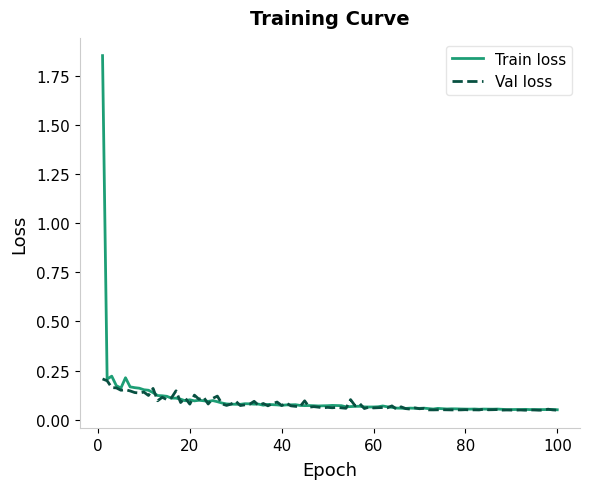

Saved: plot1_training_curve.png


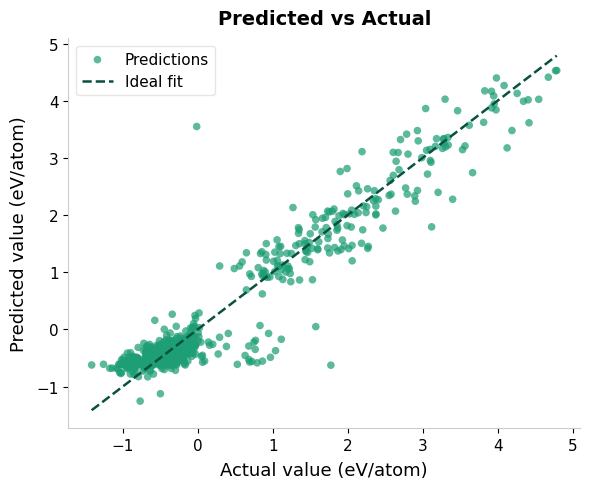

Saved: plot2_pred_vs_actual.png


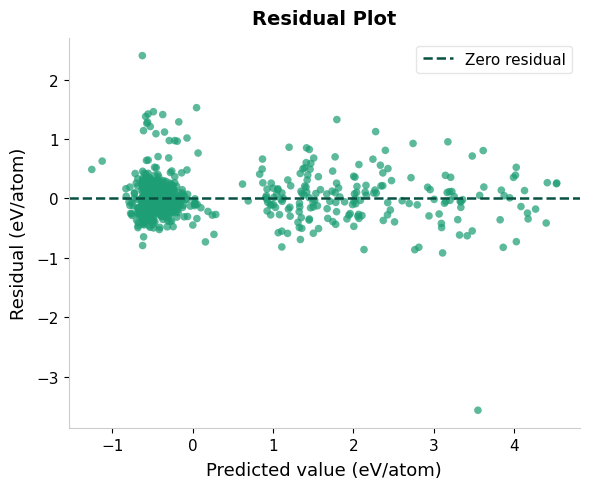

Saved: plot3_residuals.png


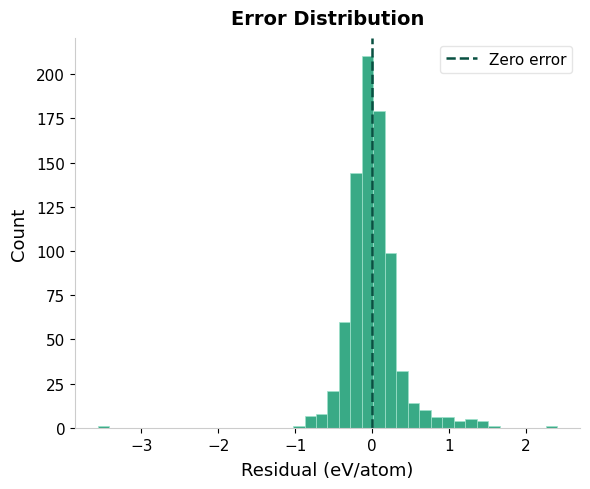

Saved: plot4_error_dist.png


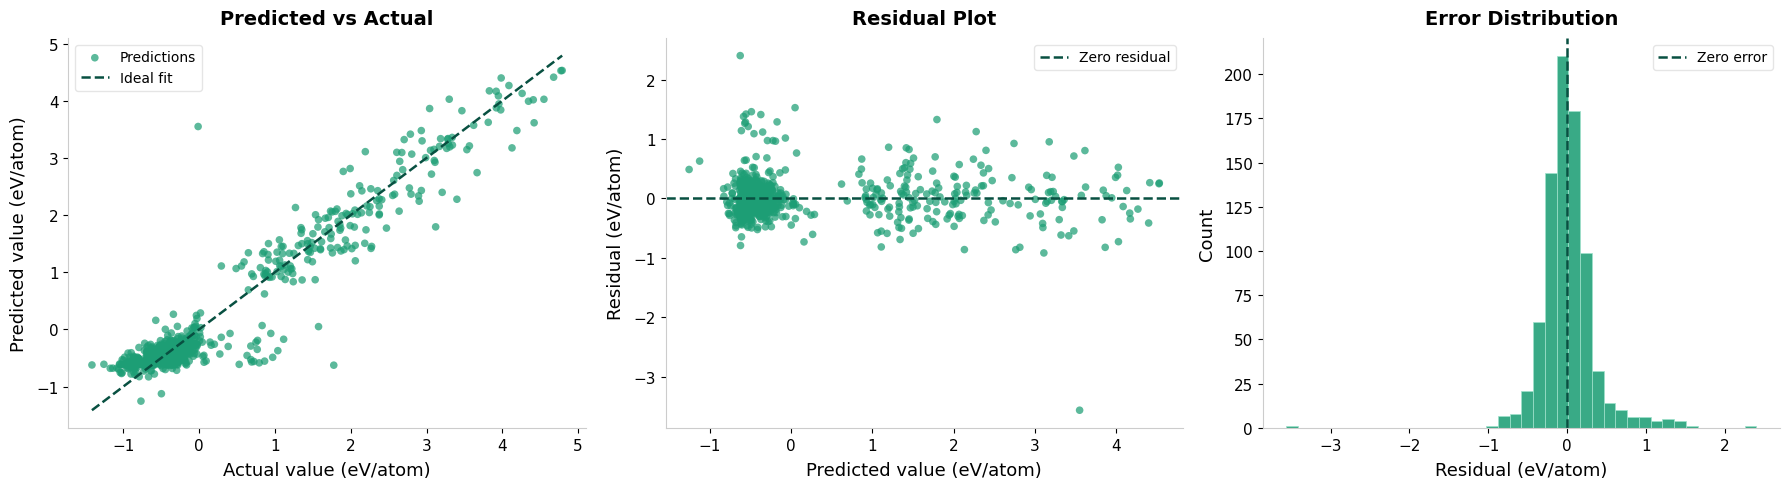

Saved: M1_DataDriven_row.png


In [30]:
# PLOTS — individual saves + row figure for paper
#__________________________________________

import matplotlib.pyplot as plt
import os

# ── color palette (Strategy 2 / Teal / lightest shade for Model 1) ────────
C_MAIN  = "#1D9E75"   # scatter, bars, train line
C_DARK  = "#085041"   # reference / zero lines, val line
C_LIGHT = "#9FE1CB"   # histogram edge
C_ALPHA = 0.72

SAVE_DIR = "DataDriven_Output"
os.makedirs(SAVE_DIR, exist_ok=True)

residuals = y_true - y_pred
lims      = [min(y_true.min(), y_pred.min()),
             max(y_true.max(), y_pred.max())]

# ── shared style ──────────────────────────────────────────────────────────
def apply_style(ax, xlabel, ylabel, title):
    ax.set_facecolor("white")
    ax.set_xlabel(xlabel, fontsize=13, labelpad=6)
    ax.set_ylabel(ylabel, fontsize=13, labelpad=6)
    ax.set_title(title, fontsize=14, fontweight="bold", pad=10)
    ax.tick_params(labelsize=11)
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color("#cccccc")

# ══════════════════════════════════════════════════════════════════════════
# PLOT 1 — Training Curve
# ══════════════════════════════════════════════════════════════════════════
fig, ax = plt.subplots(figsize=(6, 5), facecolor="white")
ax.plot(range(1, len(train_losses)+1), train_losses,
        color=C_MAIN, linewidth=2, linestyle="-",  label="Train loss")
ax.plot(range(1, len(val_losses)+1),   val_losses,
        color=C_DARK, linewidth=2, linestyle="--", label="Val loss")
apply_style(ax, xlabel="Epoch", ylabel="Loss", title="Training Curve")
ax.legend(fontsize=11, framealpha=0.5)
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, "plot1_training_curve.png"),
            dpi=600, bbox_inches="tight", facecolor="white")
plt.show()
print("Saved: plot1_training_curve.png")

# ══════════════════════════════════════════════════════════════════════════
# PLOT 2 — Predicted vs Actual
# ══════════════════════════════════════════════════════════════════════════
fig, ax = plt.subplots(figsize=(6, 5), facecolor="white")
ax.scatter(y_true, y_pred,
           color=C_MAIN, alpha=C_ALPHA, s=30, edgecolors="none",
           label="Predictions")
ax.plot(lims, lims,
        color=C_DARK, linewidth=1.8, linestyle="--", label="Ideal fit")
apply_style(ax,
    xlabel="Actual value (eV/atom)",
    ylabel="Predicted value (eV/atom)",
    title="Predicted vs Actual")
ax.legend(fontsize=11, framealpha=0.5)
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, "plot2_pred_vs_actual.png"),
            dpi=600, bbox_inches="tight", facecolor="white")
plt.show()
print("Saved: plot2_pred_vs_actual.png")

# ══════════════════════════════════════════════════════════════════════════
# PLOT 3 — Residual Plot
# ══════════════════════════════════════════════════════════════════════════
fig, ax = plt.subplots(figsize=(6, 5), facecolor="white")
ax.scatter(y_pred, residuals,
           color=C_MAIN, alpha=C_ALPHA, s=30, edgecolors="none")
ax.axhline(0, color=C_DARK, linewidth=1.8, linestyle="--",
           label="Zero residual")
apply_style(ax,
    xlabel="Predicted value (eV/atom)",
    ylabel="Residual (eV/atom)",
    title="Residual Plot")
ax.legend(fontsize=11, framealpha=0.5)
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, "plot3_residuals.png"),
            dpi=600, bbox_inches="tight", facecolor="white")
plt.show()
print("Saved: plot3_residuals.png")

# ══════════════════════════════════════════════════════════════════════════
# PLOT 4 — Error Distribution
# ══════════════════════════════════════════════════════════════════════════
fig, ax = plt.subplots(figsize=(6, 5), facecolor="white")
ax.hist(residuals, bins=40,
        color=C_MAIN, edgecolor=C_LIGHT, linewidth=0.6, alpha=0.88)
ax.axvline(0, color=C_DARK, linewidth=1.8, linestyle="--", label="Zero error")
apply_style(ax,
    xlabel="Residual (eV/atom)",
    ylabel="Count",
    title="Error Distribution")
ax.legend(fontsize=11, framealpha=0.5)
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, "plot4_error_dist.png"),
            dpi=600, bbox_inches="tight", facecolor="white")
plt.show()
print("Saved: plot4_error_dist.png")

# ══════════════════════════════════════════════════════════════════════════
# ROW FIGURE — Plots 2, 3, 4 in one row (for paper)
# ══════════════════════════════════════════════════════════════════════════
fig, axes = plt.subplots(1, 3, figsize=(18, 5), facecolor="white")

ax = axes[0]
ax.scatter(y_true, y_pred,
           color=C_MAIN, alpha=C_ALPHA, s=30, edgecolors="none",
           label="Predictions")
ax.plot(lims, lims, color=C_DARK, linewidth=1.8,
        linestyle="--", label="Ideal fit")
apply_style(ax,
    xlabel="Actual value (eV/atom)",
    ylabel="Predicted value (eV/atom)",
    title="Predicted vs Actual")
ax.legend(fontsize=10, framealpha=0.5)

ax = axes[1]
ax.scatter(y_pred, residuals,
           color=C_MAIN, alpha=C_ALPHA, s=30, edgecolors="none")
ax.axhline(0, color=C_DARK, linewidth=1.8, linestyle="--",
           label="Zero residual")
apply_style(ax,
    xlabel="Predicted value (eV/atom)",
    ylabel="Residual (eV/atom)",
    title="Residual Plot")
ax.legend(fontsize=10, framealpha=0.5)

ax = axes[2]
ax.hist(residuals, bins=40,
        color=C_MAIN, edgecolor=C_LIGHT, linewidth=0.6, alpha=0.88)
ax.axvline(0, color=C_DARK, linewidth=1.8, linestyle="--", label="Zero error")
apply_style(ax,
    xlabel="Residual (eV/atom)",
    ylabel="Count",
    title="Error Distribution")
ax.legend(fontsize=10, framealpha=0.5)

plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, "M1_DataDriven_row.png"),
            dpi=600, bbox_inches="tight", facecolor="white")
plt.show()
print("Saved: M1_DataDriven_row.png")

In [24]:
def permutation_importance(model, graphs):

    base_r2 = evaluate(model, test_loader)[2]

    importance = []

    for f in range(graphs[0].num_features):

        modified = []

        for g in graphs:

            g2 = g.clone()

            perm = torch.randperm(g2.x.size(0))
            g2.x[:, f] = g2.x[perm, f]

            modified.append(g2)

        temp_loader = DataLoader(
            modified,
            batch_size=16,
            shuffle=False
        )

        r2 = evaluate(model, temp_loader)[2]

        importance.append(base_r2 - r2)

    return importance

In [25]:
feature_importance = permutation_importance(
    model,
    test_data
)

for i, imp in enumerate(feature_importance):
    print(f"Feature {i}: {imp:.6f}")

Feature 0: -0.023147
Feature 1: 0.000939
Feature 2: -0.022891
Feature 3: -0.012070
Feature 4: -0.003283


In [33]:
# ==========================================
# SAVE MODEL + WEIGHTS + RESULTS
# ==========================================

import os
import torch

SAVE_DIR = "DataDriven_Output"
os.makedirs(SAVE_DIR, exist_ok=True)

# ------------------------------------------
# Full checkpoint
# ------------------------------------------

torch.save(
    {
        "model_state": model.state_dict(),

        "mae": mae,
        "mse": mse,
        "rmse": rmse,

        "train_loss": final_train_loss,
        "val_loss": final_val_loss,
    },
    os.path.join(
        SAVE_DIR,
        "DataDriven_final.pth"
    )
)

# ------------------------------------------
# Weights only
# ------------------------------------------

torch.save(
    model.state_dict(),
    os.path.join(
        SAVE_DIR,
        "DataDriven_weights.pth"
    )
)

# ------------------------------------------
# Human-readable results
# ------------------------------------------

results_text = f"""
====================================
DataDriven Model Results
====================================

MAE         : {mae:.6f}
MSE         : {mse:.6f}
RMSE        : {rmse:.6f}

Train Loss  : {final_train_loss:.6f}
Val Loss    : {final_val_loss:.6f}

Train Size  : {len(train_data)}
Val Size    : {len(val_data)}
Test Size   : {len(test_data)}

Total Graphs : {len(graphs)}
"""

with open(
    os.path.join(
        SAVE_DIR,
        "DataDriven_results.txt"
    ),
    "w"
) as f:
    f.write(results_text)

print(results_text)

print("Saved DataDriven_final.pth")
print("Saved DataDriven_weights.pth")
print("Saved DataDriven_results.txt")


DataDriven Model Results

MAE         : 0.222913
MSE         : 0.122195
RMSE        : 0.349564

Train Loss  : 0.051175
Val Loss    : 0.048976

Train Size  : 6503
Val Size    : 813
Test Size   : 813

Total Graphs : 8129

Saved DataDriven_final.pth
Saved DataDriven_weights.pth
Saved DataDriven_results.txt


In [34]:
import shutil

shutil.make_archive(
    "DataDriven_Output",
    "zip",
    "DataDriven_Output"
)

print("Created: DataDriven_Output.zip")

Created: DataDriven_Output.zip


In [35]:
import os

for f in sorted(os.listdir("DataDriven_Output")):
    print(f)

DataDriven_final.pth
DataDriven_results.txt
DataDriven_weights.pth


#Inferenece
* Inferencing the model and run for different materials